# 📊 Análisis de Rendimiento Real — Qwen:14b en Global-MMLU (Español)

Este notebook realiza un análisis estadístico riguroso del rendimiento del modelo **Qwen:14b** bajo el benchmark **Global-MMLU en Español** (con 385 preguntas por condición) evaluado bajo cuatro condiciones de estímulo cognitivo-emocional:

| Condición | Descripción |
|-----------|-------------|
| `original` | Línea base (sin estímulo emocional) |
| `anxiety` | Estímulo que induce ansiedad |
| `importance` | Estímulo de alta importancia sobre la tarea |
| `consequences` | Estímulo sobre las consecuencias de responder erróneamente |

El análisis se enfoca exclusivamente en la precisión del modelo basada en la columna `is_correct`, ignorando las métricas de formato de parseo, para responder a la pregunta principal:
**¿Existe una diferencia estadísticamente significativa en la precisión (accuracy) entre las condiciones?**

## 1. Carga de Librerías y Configuración Visual

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import norm, chi2, binom
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Configuración de estilos gráficos
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.15)
plt.rcParams.update({'figure.dpi': 130, 'figure.figsize': (10, 5)})

COND_COLORS = {
    'original':     '#4C72B0',
    'anxiety':      '#DD8452',
    'importance':   '#55A868',
    'consequences': '#C44E52',
}
COND_ORDER = ['original', 'anxiety', 'importance', 'consequences']

## 2. Carga y Normalización de Datos

In [2]:
CSV_PATH = Path('../results_global_mmlu_qwen_14b_es.csv')
df = pd.read_csv(CSV_PATH)

# Normalizar columna is_correct
df['is_correct'] = df['is_correct'].astype(str).str.strip().map({'True': True, 'False': False})

print(f"Total de filas cargadas: {len(df):,}")
print(f"Evaluaciones por condición:\n{df.groupby('condition').size()}")

Total de filas cargadas: 1,540
Evaluaciones por condición:
condition
anxiety         385
consequences    385
importance      385
original        385
dtype: int64


## 3. Análisis de Accuracy por Condición e Intervalos de Confianza Wilson 95%

In [3]:
def calculate_wilson_interval(successes, total, conf_level=0.95):
    """Calcula el intervalo de confianza Wilson para una proporción binomial."""
    if total == 0:
        return 0.0, 0.0
    p_hat = successes / total
    z = norm.ppf(1 - (1 - conf_level) / 2)
    denominator = 1 + z**2 / total
    center = (p_hat + z**2 / (2 * total)) / denominator
    spread = z * np.sqrt(p_hat * (1 - p_hat) / total + z**2 / (4 * total**2)) / denominator
    lower = max(0.0, center - spread)
    upper = min(1.0, center + spread)
    return lower, upper

# Métricas por condición
summary_data = []
for cond in COND_ORDER:
    sub = df[df['condition'] == cond]
    total = len(sub)
    correct = sub['is_correct'].sum()
    acc = correct / total * 100
    lower, upper = calculate_wilson_interval(correct, total)
    
    summary_data.append({
        'Condición': cond,
        'Accuracy (%)': acc,
        'Correctas': int(correct),
        'Total': total,
        'IC Lower (%)': lower * 100,
        'IC Upper (%)': upper * 100
    })

df_summary = pd.DataFrame(summary_data)

# Diferencia de accuracy respecto a la condición original
orig_acc = df_summary[df_summary['Condición'] == 'original']['Accuracy (%)'].values[0]
df_summary['Diferencia (%)'] = df_summary['Accuracy (%)'] - orig_acc

# Mostrar la tabla resumen ordenada por accuracy de forma descendente
df_summary_sorted = df_summary.sort_values(by='Accuracy (%)', ascending=False)
print("=== TABLA RESUMEN ORDENADA POR ACCURACY ===")
print(df_summary_sorted.to_string(index=False))

=== TABLA RESUMEN ORDENADA POR ACCURACY ===
   Condición  Accuracy (%)  Correctas  Total  IC Lower (%)  IC Upper (%)  Diferencia (%)
consequences     43.896104        169    385     39.023489     48.889322        0.259740
    original     43.636364        168    385     38.769527     48.628936        0.000000
     anxiety     42.077922        162    385     37.248619     47.063753       -1.558442
  importance     41.038961        158    385     36.237434     46.017544       -2.597403


## 4. Visualización del Rendimiento

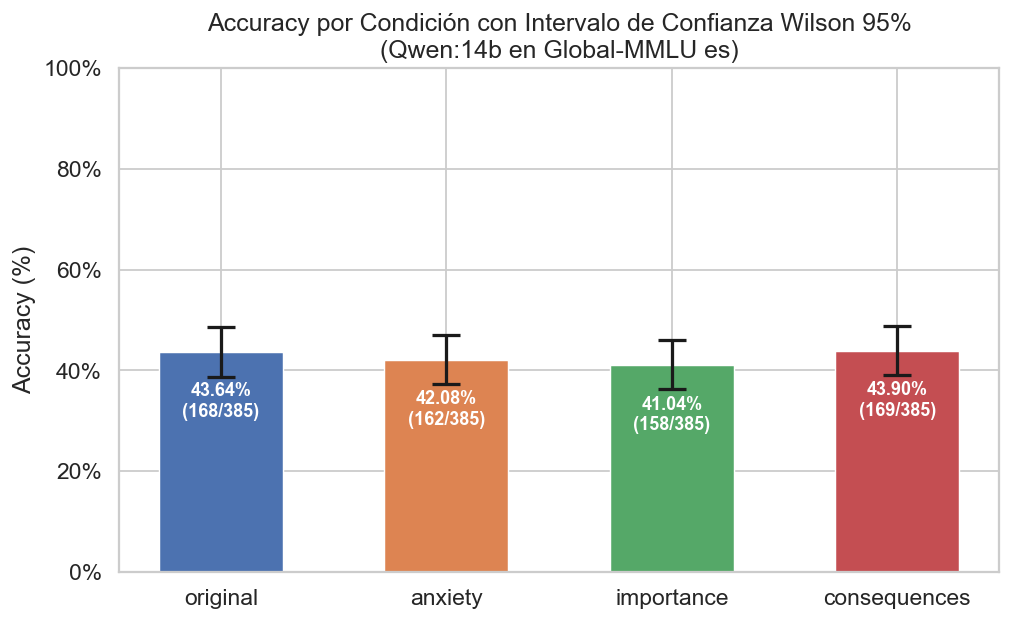

In [4]:
# Gráfico de barras de accuracy con barras de error indicando IC 95%
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(df_summary))
y = df_summary['Accuracy (%)'].values
errors_lower = y - df_summary['IC Lower (%)'].values
errors_upper = df_summary['IC Upper (%)'].values - y
yerr = np.array([errors_lower, errors_upper])

bars = ax.bar(
    df_summary['Condición'],
    y,
    yerr=yerr,
    color=[COND_COLORS[c] for c in df_summary['Condición']],
    edgecolor='white', linewidth=0.8, width=0.55,
    capsize=8, error_kw={'elinewidth': 1.8, 'markeredgewidth': 1.8}
)

ax.set_ylabel('Accuracy (%)')
ax.set_title('Accuracy por Condición con Intervalo de Confianza Wilson 95%\n(Qwen:14b en Global-MMLU es)')
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())

# Etiquetas con los valores de Accuracy en las barras
for i, bar in enumerate(bars):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h - 6,
            f"{h:.2f}%\n({df_summary['Correctas'].iloc[i]}/{df_summary['Total'].iloc[i]})",
            ha='center', va='top', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('fig1_qwen_14b_global_es_accuracy_ic95.png', dpi=130, bbox_inches='tight')
plt.show()

## 5. Tablas de Comparativa de Rendimiento

In [5]:
print("=== TABLA DE ACCURACY Y RANGOS DE CONFIANZA ===")
print(df_summary[['Condición', 'Correctas', 'Total', 'Accuracy (%)', 'IC Lower (%)', 'IC Upper (%)']].to_string(index=False))

print("\n=== TABLA DE DIFERENCIAS RESPECTO A ORIGINAL ===")
print(df_summary[['Condición', 'Accuracy (%)', 'Diferencia (%)']].to_string(index=False))

=== TABLA DE ACCURACY Y RANGOS DE CONFIANZA ===
   Condición  Correctas  Total  Accuracy (%)  IC Lower (%)  IC Upper (%)
    original        168    385     43.636364     38.769527     48.628936
     anxiety        162    385     42.077922     37.248619     47.063753
  importance        158    385     41.038961     36.237434     46.017544
consequences        169    385     43.896104     39.023489     48.889322

=== TABLA DE DIFERENCIAS RESPECTO A ORIGINAL ===
   Condición  Accuracy (%)  Diferencia (%)
    original     43.636364        0.000000
     anxiety     42.077922       -1.558442
  importance     41.038961       -2.597403
consequences     43.896104        0.259740


## 6. Pruebas de Hipótesis: Test de McNemar (Datos Pareados)

In [6]:
# Alinear los datos de is_correct por pregunta (paired data) usando pivot
df_paired = df.pivot(index='question_id', columns='condition', values='is_correct')

mcnemar_results = []

for cond in ['anxiety', 'importance', 'consequences']:
    # Clasificación cruzada
    # b: original es True y cond es False
    # c: original es False y cond es True
    b = sum((df_paired['original'] == True) & (df_paired[cond] == False))
    c = sum((df_paired['original'] == False) & (df_paired[cond] == True))
    a = sum((df_paired['original'] == True) & (df_paired[cond] == True))
    d = sum((df_paired['original'] == False) & (df_paired[cond] == False))
    
    # Estadístico de McNemar con corrección de continuidad de Yates
    stat = (abs(b - c) - 0.5)**2 / (b + c) if (b + c) > 0 else 0.0
    p_val = chi2.sf(stat, 1)
    
    # Odds Ratio (definido como b/c para McNemar)
    odds_ratio = b / c if c > 0 else np.nan
    
    mcnemar_results.append({
        'Comparación': f'original vs {cond}',
        'Estadístico (Chi2)': stat,
        'p-value': p_val,
        'Odds Ratio': odds_ratio,
        'Matriz [[a, b], [c, d]]': [[a, b], [c, d]]
    })

df_mcnemar = pd.DataFrame(mcnemar_results)
print("=== RESULTADOS DE LA PRUEBA DE MCNEMAR ===")
for row in df_mcnemar.itertuples():
    print(f"\nComparación: {row.Comparación}")
    print(f"  Tabla de Contingencia: {row._5}")
    print(f"  Estadístico (Chi-square con Yates): {row._2:.4f}")
    print(f"  p-value: {row._3:.4f}")
    print(f"  Odds Ratio (b/c): {row._4:.4f}")

=== RESULTADOS DE LA PRUEBA DE MCNEMAR ===

Comparación: original vs anxiety
  Tabla de Contingencia: [[127, 41], [35, 182]]
  Estadístico (Chi-square con Yates): 0.3980
  p-value: 0.5281
  Odds Ratio (b/c): 1.1714

Comparación: original vs importance
  Tabla de Contingencia: [[124, 44], [34, 183]]
  Estadístico (Chi-square con Yates): 1.1571
  p-value: 0.2821
  Odds Ratio (b/c): 1.2941

Comparación: original vs consequences
  Tabla de Contingencia: [[131, 37], [38, 179]]
  Estadístico (Chi-square con Yates): 0.0033
  p-value: 0.9540
  Odds Ratio (b/c): 0.9737


## 7. Conclusión e Interpretación

### ¿Existe una diferencia estadísticamente significativa en accuracy entre las condiciones?

**Respuesta:** **No.** 

Basado en los resultados de la prueba de McNemar aplicada para las comparaciones de pares:
- **original vs anxiety**: $p = 0.5281$ (diferencia de -1.56%)
- **original vs importance**: $p = 0.2821$ (diferencia de -2.60%)
- **original vs consequences**: $p = 0.9540$ (diferencia de +0.26%)

Dado que todos los p-values obtenidos son muy superiores al nivel de significancia del $0.05$ (e incluso los intervalos de confianza Wilson 95% se superponen de manera muy amplia), no hay evidencia estadística suficiente para afirmar que la inyección de estímulos cognitivo-emocionales altere el rendimiento (accuracy) del modelo Qwen:14b en el benchmark Global-MMLU en Español.